In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="ISO-8859-1")

print("Dataset Shape:", df.shape)
display(df.head())
print(df.isnull().sum())

Dataset Shape: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64


In [3]:
features = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]

X = df[features].copy()
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected Features:", features)

Selected Features: ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']


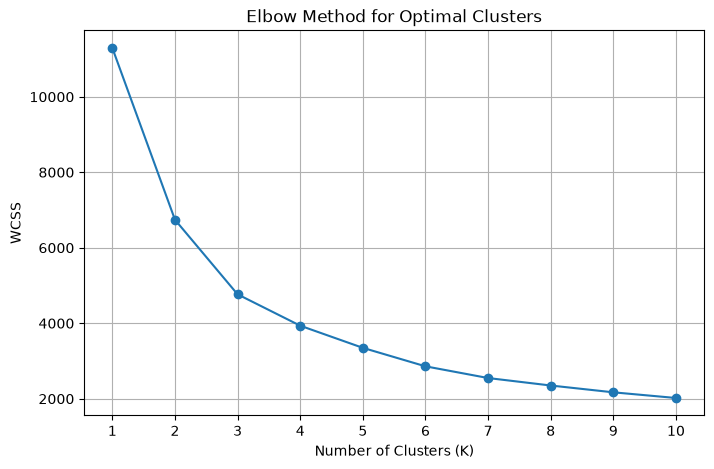

In [4]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [5]:
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(df[features + ["KMeans_Cluster"]].head())
print("\nCluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP  KMeans_Cluster
0               30      95.70  2871.00    95               2
1               34      81.35  2765.90    95               2
2               41      94.74  3884.34    95               1
3               45      83.26  3746.70    95               1
4               49     100.00  5205.27    95               1

Cluster Counts:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64


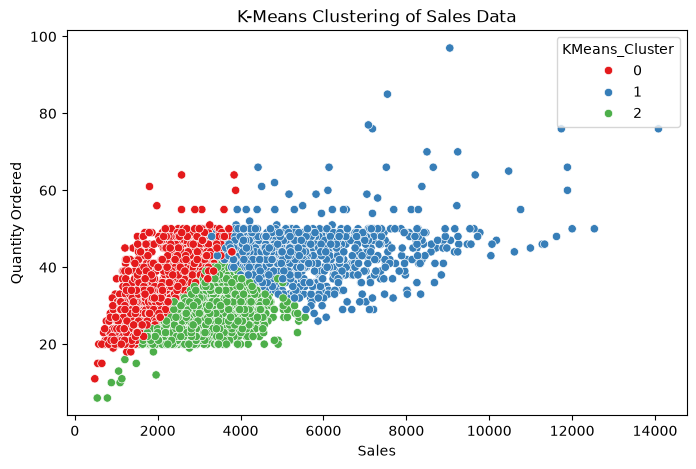

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df["SALES"],
    y=df["QUANTITYORDERED"],
    hue=df["KMeans_Cluster"],
    palette="Set1"
)

plt.title("K-Means Clustering of Sales Data")
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.show()

In [7]:
hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print(df[features + ["Hierarchical_Cluster"]].head())
print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP  Hierarchical_Cluster
0               30      95.70  2871.00    95                     2
1               34      81.35  2765.90    95                     2
2               41      94.74  3884.34    95                     0
3               45      83.26  3746.70    95                     0
4               49     100.00  5205.27    95                     1

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


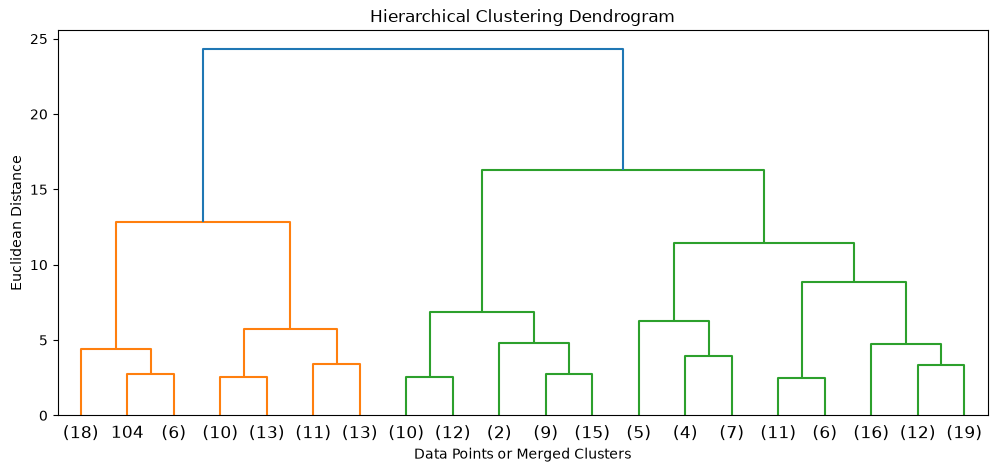

In [8]:
sample = X_scaled[:200]

Z = linkage(sample, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points or Merged Clusters")
plt.ylabel("Euclidean Distance")
plt.show()